# Clustering the Inventory Items Using DBSCAN
#### helps to identify the dead stock items and slow moving items 

Visualization saved as 'dbscan_5features_pca_visualization.png'

--- Summary of 5-Feature DBSCAN Cluster Analysis ---
   Cluster_Label  count  mean_Annual_Consumption  mean_availableQuantity
4              3    449                 0.000000                0.000000
2              1     22                12.000000                1.000000
3              2    278                12.000000                1.000000
0             -1     92                42.554348                3.543478
1              0   2891                59.476306                4.958146
Analysis results saved to 'dbscan_5features_analysis_results.csv'


/var/folders/rk/4c5rxxls69nd5rcvx8mdpyvm0000gn/T/ipykernel_49243/900108329.py:51: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = plt.cm.get_cmap('Spectral')


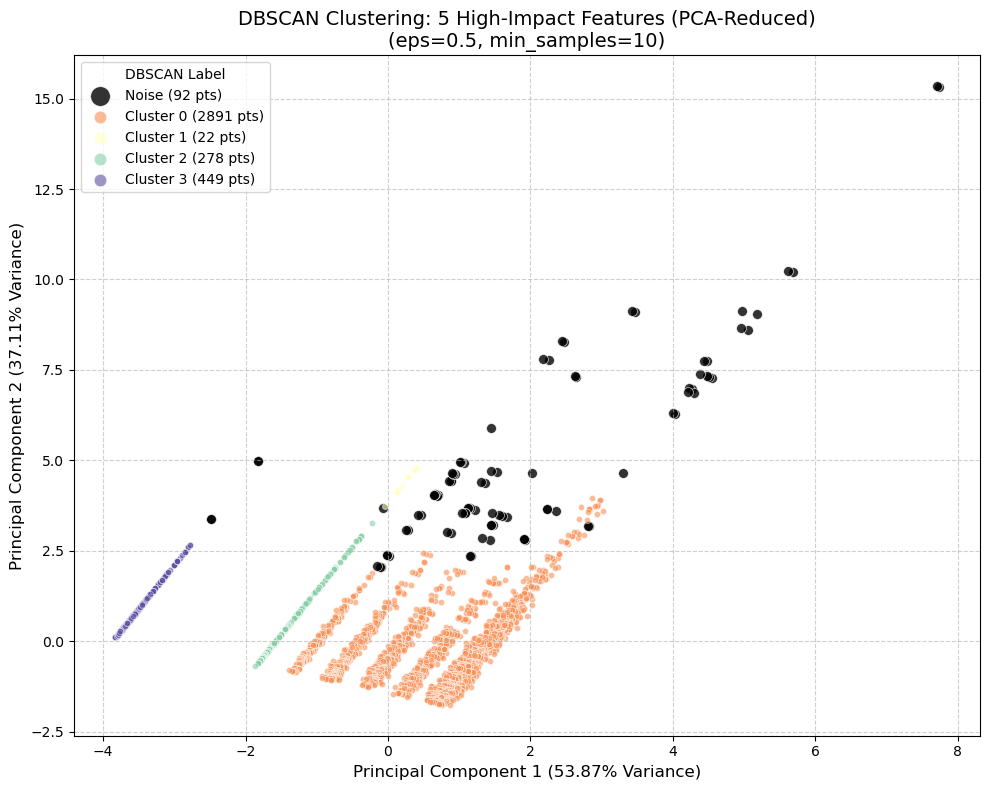

In [1]:
# dbscan 

import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import DBSCAN
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt
import numpy as np

# --- 1. Load Data and Select High-Impact Features ---
file_name = 'Project IMS.csv'
df = pd.read_csv(file_name)

# Calculate Annual Consumption (if needed, ensure it's in the data frame)
consumption_cols = [f'Month_{i}' for i in range(1, 13)]
df['Annual_Consumption'] = df[consumption_cols].sum(axis=1)

# The 5 high-impact features
high_impact_cols = [
    'availableQuantity', 'Annual_Consumption', 'outOfStock', 'mrp', 'discountedSellingPrice'
]
X = df[high_impact_cols].copy()

# Prepare data: Ensure 'outOfStock' is numerical (True -> 1, False -> 0)
X['outOfStock'] = X['outOfStock'].astype(int)

# --- 2. Scale the Data ---
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# --- 3. Run DBSCAN ---
eps_val = 0.5
min_samples_val = 10
dbscan = DBSCAN(eps=eps_val, min_samples=min_samples_val)
dbscan_labels = dbscan.fit_predict(X_scaled)
df['DBSCAN_Label_5Features'] = dbscan_labels

# --- 4. PCA for Visualization (5D -> 2D) ---
pca = PCA(n_components=2)
principal_components = pca.fit_transform(X_scaled)

# Create a DataFrame for the reduced data
pca_df = pd.DataFrame(data=principal_components, columns=['PC1', 'PC2'])
pca_df['Cluster'] = dbscan_labels

# --- 5. Generate Visualization ---
def create_dbscan_plot(pca_df, pca_model, title, filename):
    plt.figure(figsize=(10, 8))

    unique_labels = np.unique(pca_df['Cluster'])
    cmap = plt.cm.get_cmap('Spectral')
    colors = [cmap(i) for i in np.linspace(0, 1, len(unique_labels))]
    color_map = {label: colors[i] if label != -1 else 'black' for i, label in enumerate(unique_labels)}

    for cluster_label in sorted(pca_df['Cluster'].unique()):
        subset = pca_df[pca_df['Cluster'] == cluster_label]
        label_text = f'Noise ({len(subset)} pts)' if cluster_label == -1 else f'Cluster {cluster_label} ({len(subset)} pts)'
        
        s_size = 50 if cluster_label == -1 else 20
        alpha = 0.6 if cluster_label != -1 else 0.8

        plt.scatter(
            subset['PC1'],
            subset['PC2'],
            c=[color_map[cluster_label]],
            label=label_text,
            s=s_size,
            alpha=alpha,
            edgecolors='w',
            linewidth=0.5
        )

    plt.title(title, fontsize=14)
    plt.xlabel(f'Principal Component 1 ({pca_model.explained_variance_ratio_[0]*100:.2f}% Variance)', fontsize=12)
    plt.ylabel(f'Principal Component 2 ({pca_model.explained_variance_ratio_[1]*100:.2f}% Variance)', fontsize=12)
    plt.legend(title='DBSCAN Label', loc='best', fontsize=10, markerscale=2)
    plt.grid(True, linestyle='--', alpha=0.6)
    plt.tight_layout()
    plt.savefig(filename)
    print(f"Visualization saved as '{filename}'")

# Execute plot generation
create_dbscan_plot(
    pca_df,
    pca,
    f'DBSCAN Clustering: 5 High-Impact Features (PCA-Reduced)\n(eps={eps_val}, min_samples={min_samples_val})',
    'dbscan_5features_pca_visualization.png'
)

# --- 6. Generate and Print Summary ---
grouped = df.groupby('DBSCAN_Label_5Features').agg(
    count=('Annual_Consumption', 'count'),
    mean_Annual_Consumption=('Annual_Consumption', 'mean'),
    mean_availableQuantity=('availableQuantity', 'mean')
).reset_index().rename(columns={'DBSCAN_Label_5Features': 'Cluster_Label'})

print("\n--- Summary of 5-Feature DBSCAN Cluster Analysis ---")
print(grouped.sort_values(by='mean_Annual_Consumption').to_string())

# --- 7. Save Results ---
df_output = df[['Category', 'name', 'Annual_Consumption', 'availableQuantity', 'DBSCAN_Label_5Features']]
df_output.to_csv('dbscan_5features_analysis_results.csv', index=False)
print("Analysis results saved to 'dbscan_5features_analysis_results.csv'")